In [6]:
import torch
from sqlalchemy.sql.functions import percent_rank
from torch import nn
from torch.utils.data import DataLoader, random_split

SEED = 42
torch.manual_seed(SEED)

device = ("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [7]:
import urllib.request
import zipfile
from pathlib import Path
from torchvision import datasets, transforms

url = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"

Path("data").mkdir(exist_ok=True)

urllib.request.urlretrieve(url, "data/hymenoptera_data.zip")

with zipfile.ZipFile("data/hymenoptera_data.zip") as z:
    z.extractall("data")

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_data = datasets.ImageFolder(
    "data/hymenoptera_data/train",
    transform=train_transform
)

val_data = datasets.ImageFolder(
    "data/hymenoptera_data/val",
    transform=val_transform
)

train_loader = DataLoader(train_data, batch_size=16, shuffle=True)
val_loader = DataLoader(val_data, batch_size=16, shuffle=False)

print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Classes:", train_data.classes)

Train: 244
Validation: 153
Classes: ['ants', 'bees']


In [9]:
from torchvision.models import resnet18, ResNet18_Weights

model_freezing = resnet18(weights=ResNet18_Weights.DEFAULT)

for param in model_freezing.parameters():
    param.requires_grad = False

model_freezing.fc = nn.Linear(model_freezing.fc.in_features, 2)

model_freezing = model_freezing.to(device)

print(model_freezing.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/nicklas/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 29.0MB/s]


Linear(in_features=512, out_features=2, bias=True)


In [15]:
model_fine_tuning = resnet18(weights=ResNet18_Weights.DEFAULT)

for param in model_fine_tuning.parameters():
    param.requires_grad = False

for param in model_fine_tuning.layer4.parameters():
    param.requires_grad = True

model_fine_tuning.fc = nn.Linear(model_fine_tuning.fc.in_features, 2)

model_fine_tuning = model_fine_tuning.to(device)

print(model_fine_tuning.fc)

Linear(in_features=512, out_features=2, bias=True)


In [16]:
@torch.inference_mode()
def evaluate(model, loader):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    criterion = nn.CrossEntropyLoss()

    for X, y in loader:
        X, y = X.to(device), y.to(device)

        logits = model(X)
        loss = criterion(logits, y)

        predictions = logits.argmax(dim=1)

        total_loss += loss.item() * y.size(0)
        correct += (predictions == y).sum().item()
        total += y.size(0)

    return {
        "loss": total_loss / total,
        "accuracy": correct / total,
    }

In [17]:
import time

def train_model(model, optimizer, epochs=5):
    criterion = nn.CrossEntropyLoss()
    history = []

    for epoch in range(epochs):
        model.train()

        for module in model.modules():
            if isinstance(module, nn.BatchNorm2d):
                module.eval()

        total_loss = 0
        total = 0

        start = time.perf_counter()

        for X, y in train_loader:
            X, y = X.to(device), y.to(device)

            optimizer.zero_grad()

            logits = model(X)
            loss = criterion(logits, y)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * y.size(0)
            total += y.size(0)

        train_loss = total_loss / total

        metrics = evaluate(model, val_loader)
        elapsed = time.perf_counter() - start

        history.append({
            "train_loss": train_loss,
            "val_loss": metrics["loss"],
            "val_accuracy": metrics["accuracy"],
            "time": elapsed,
        })

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {metrics['loss']:.4f} | "
            f"Val Acc: {metrics['accuracy']:.2%} | "
            f"Time: {elapsed:.1f}s"
        )

    return history

In [18]:
model_fine_tuning.fc.load_state_dict(
    model_freezing.fc.state_dict()
)

<All keys matched successfully>

In [19]:
optimizer_frozen = torch.optim.Adam(
    model_freezing.fc.parameters(),
    lr=1e-3
)

history_frozen = train_model(
    model_freezing,
    optimizer_frozen,
    epochs=5
)

Epoch 1/5 | Train Loss: 0.5647 | Val Loss: 0.3328 | Val Acc: 93.46% | Time: 3.2s
Epoch 2/5 | Train Loss: 0.2987 | Val Loss: 0.1976 | Val Acc: 94.77% | Time: 2.2s
Epoch 3/5 | Train Loss: 0.1878 | Val Loss: 0.1618 | Val Acc: 94.77% | Time: 2.5s
Epoch 4/5 | Train Loss: 0.1703 | Val Loss: 0.1484 | Val Acc: 94.77% | Time: 2.5s
Epoch 5/5 | Train Loss: 0.1426 | Val Loss: 0.1461 | Val Acc: 95.42% | Time: 2.2s


In [28]:
optimizer_finetune = torch.optim.Adam([
    {
        "params": model_fine_tuning.layer4.parameters(),
        "lr": 1e-4
    },
    {
        "params": model_fine_tuning.fc.parameters(),
        "lr": 1e-3
    }
])

history_finetune = train_model(
    model_fine_tuning,
    optimizer_finetune,
    epochs=5
)

Epoch 1/5 | Train Loss: 0.0985 | Val Loss: 0.6522 | Val Acc: 88.89% | Time: 2.4s
Epoch 2/5 | Train Loss: 0.0757 | Val Loss: 0.3678 | Val Acc: 94.77% | Time: 2.2s
Epoch 3/5 | Train Loss: 0.1542 | Val Loss: 0.5691 | Val Acc: 83.66% | Time: 2.4s
Epoch 4/5 | Train Loss: 0.0563 | Val Loss: 0.3491 | Val Acc: 92.16% | Time: 2.2s
Epoch 5/5 | Train Loss: 0.0649 | Val Loss: 0.3854 | Val Acc: 92.81% | Time: 2.4s


In [21]:
frozen = evaluate(model_freezing, val_loader)
finetune = evaluate(model_fine_tuning, val_loader)

print(
    f"Frozen:      "
    f"Accuracy = {frozen['accuracy']:.2%}, "
    f"Loss = {frozen['loss']:.4f}"
)

print(
    f"Fine-Tuning: "
    f"Accuracy = {finetune['accuracy']:.2%}, "
    f"Loss = {finetune['loss']:.4f}"
)

print(
    f"Accuracy difference: "
    f"{(finetune['accuracy'] - frozen['accuracy'])*100:+.2f} pp"
)

Frozen:      Accuracy = 95.42%, Loss = 0.1461
Fine-Tuning: Accuracy = 94.12%, Loss = 0.2366
Accuracy difference: -1.31 pp


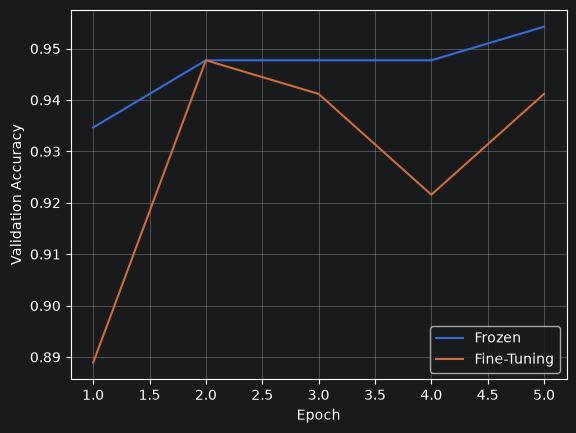

In [22]:
import matplotlib.pyplot as plt

epochs = range(1, len(history_frozen) + 1)

plt.plot(
    epochs,
    [h["val_accuracy"] for h in history_frozen],
    label="Frozen"
)

plt.plot(
    epochs,
    [h["val_accuracy"] for h in history_finetune],
    label="Fine-Tuning"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

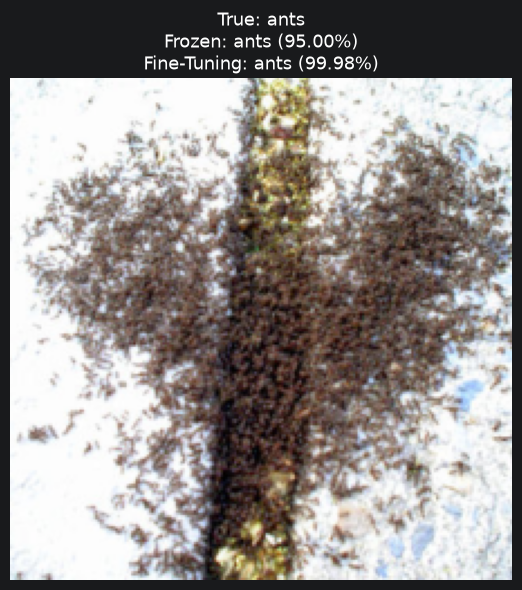

In [29]:
import matplotlib.pyplot as plt
import torch

image, label = val_data[0]
X = image.unsqueeze(0).to(device)

model_freezing.eval()
model_fine_tuning.eval()

with torch.inference_mode():
    frozen_probs = model_freezing(X).softmax(dim=1)[0]
    finetune_probs = model_fine_tuning(X).softmax(dim=1)[0]

frozen_pred = frozen_probs.argmax().item()
finetune_pred = finetune_probs.argmax().item()

classes = val_data.classes

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

image_display = (image.cpu() * std + mean).clamp(0, 1)

plt.figure(figsize=(7, 6))

plt.imshow(image_display.permute(1, 2, 0))
plt.axis("off")

plt.title(
    f"True: {classes[label]}\n"
    f"Frozen: {classes[frozen_pred]} "
    f"({frozen_probs[frozen_pred].item():.2%})\n"
    f"Fine-Tuning: {classes[finetune_pred]} "
    f"({finetune_probs[finetune_pred].item():.2%})",
    fontsize=13
)

plt.tight_layout()
plt.show()